# Definisanje osnovnih import biblioteka

In [1]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from google.colab import drive
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
import numpy as np

# Drive mounting

In [2]:
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Mašinsko učenje/clean_dataset.csv')

Mounted at /content/drive


In [3]:
df.head()

,Attrition_Flag_clean,Customer_Age_clean,Gender_clean,Dependent_count_clean,Education_Level_clean,Marital_Status_clean,Income_Category_clean,Card_Category_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
0,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Blue,39.0,4.0,1.0,3.0,4537.0,777.0,3473.0,0.737,1144.0,42.0,1.625,0.061
1,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,6.0,1.0,2.0,8256.0,1249.0,3473.0,0.737,1291.0,67.0,3.714,0.105
2,Existing Customer,46.0,M,3.0,Graduate,Married,$80K - $120K,Blue,36.0,4.0,1.0,2.0,3418.0,0.0,3418.0,2.594,1887.0,20.0,2.333,0.000
3,Existing Customer,46.0,F,4.0,High School,Unknown,Less than $40K,Blue,34.0,3.0,4.0,2.0,3313.0,1249.0,796.0,1.405,1171.0,20.0,2.333,0.760
4,Existing Customer,46.0,M,3.0,Uneducated,Married,$60K - $80K,Blue,36.0,5.0,2.0,2.0,4716.0,0.0,4716.0,2.175,3899.0,28.0,2.500,0.000


# Priprema podataka za modeliranje

In [4]:
target_column = 'Attrition_Flag_clean'
X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Podjela podataka na 70/15/15

In [5]:
from sklearn.model_selection import train_test_split

# 1) TEST set – 15%
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# 2) TRAIN + VALIDATION (od preostalih 85%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.17647,   # 15% od ukupnog
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (7088, 19)
Validation: (1519, 19)
Test: (1520, 19)


# Definisanje tri klasifikatora za modeliranje:

## 1. KNN sa 8 susjeda i težinama po udaljenosti.
## 2. SVM sa RBF kernelom, standardnim parametrima i mogućnošću predikcije vjerovatnoće.
## 3. Random Forest sa 800 stabala, maksimalnom dubinom 15 i minimalno 4 uzorka po listu.


In [6]:
knn = KNeighborsClassifier(
    n_neighbors=8,
    weights='distance'
)

svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=800,
    max_depth=15,
    min_samples_leaf=4,
    random_state=42
)

# Kreiranje ensemble modela i pipeline

In [7]:
ensemble = VotingClassifier(
    estimators=[
        ('knn', knn),
        ('svm', svm),
        ('rf', rf)
    ],
    voting='soft'
)

pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('ensemble', ensemble)
])

# Treniranje modela

In [8]:
pipeline.fit(X_train, y_train)
y_val_pred = pipeline.predict(X_val)


# Evaluacija modela

In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

POS_LABEL = "Attrited Customer"

def compute_metrics(y_true, y_pred, pos_label=POS_LABEL):
    labels = np.unique(y_true)
    neg_label = [c for c in labels if c != pos_label][0]

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred,
        labels=[neg_label, pos_label]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=pos_label),
        "Recall (Sensitivity)": recall_score(y_true, y_pred, pos_label=pos_label),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_true, y_pred, pos_label=pos_label),
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred)
    }

metrics_val = compute_metrics(y_val, y_val_pred)
metrics_val


{'Accuracy': 0.892034233048058,
 'Precision': 0.8074074074074075,
 'Recall (Sensitivity)': 0.44129554655870445,
 'Specificity': np.float64(0.9795597484276729),
 'F1-score': 0.5706806282722513,
 'Cohen Kappa': np.float64(0.5149308368122625)}

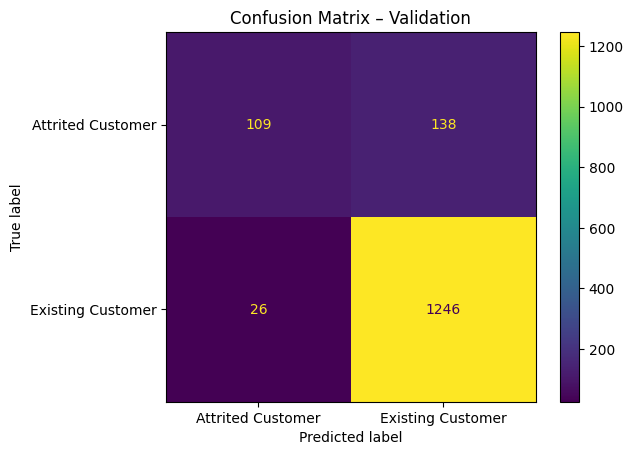

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
plt.title("Confusion Matrix – Validation")
plt.show()


In [12]:
y_test_pred = pipeline.predict(X_test)
metrics_test = compute_metrics(y_test, y_test_pred)
metrics_test


{'Accuracy': 0.8934210526315789,
 'Precision': 0.8102189781021898,
 'Recall (Sensitivity)': 0.4493927125506073,
 'Specificity': np.float64(0.9795758051846033),
 'F1-score': 0.578125,
 'Cohen Kappa': np.float64(0.5227925473157081)}

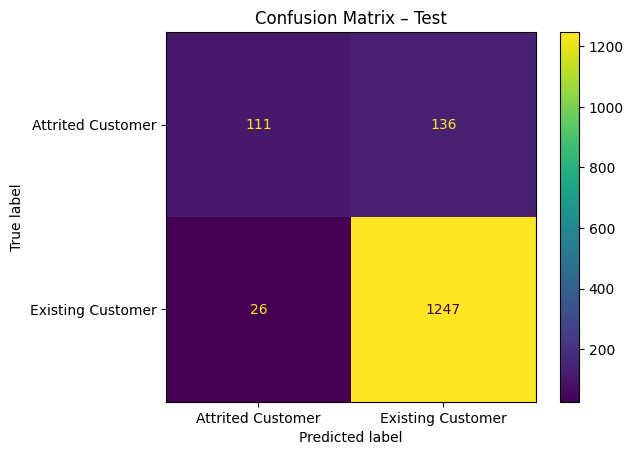

In [13]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.title("Confusion Matrix – Test")
plt.show()


# Cross-validacija

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}


cv_results = cross_validate(
    pipeline, X_train, y_train,
    cv=cv,
    scoring=scoring
)

pd.DataFrame(cv_results).mean()


,0
fit_time,14.988276
score_time,0.490141
test_accuracy,0.901805
test_precision,0.877215
test_recall,0.732449
test_f1,0.778895


In [16]:
pipeline.fit(X_train, y_train)
y_test_pred = pipeline.predict(X_test)


In [17]:
metrics_test = compute_metrics(y_test, y_test_pred)
metrics_test


{'Accuracy': 0.8934210526315789,
 'Precision': 0.8102189781021898,
 'Recall (Sensitivity)': 0.4493927125506073,
 'Specificity': np.float64(0.9795758051846033),
 'F1-score': 0.578125,
 'Cohen Kappa': np.float64(0.5227925473157081)}

## Eksperimentalna analiza: balansiranje podataka (SMOTE)


In [18]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


In [19]:
pipeline_smote = ImbPipeline(steps=[
    ('preprocessing', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('ensemble', ensemble)
])


In [20]:
pipeline_smote.fit(X_train, y_train)
y_test_pred_smote = pipeline_smote.predict(X_test)

metrics_test_smote = compute_metrics(y_test, y_test_pred_smote)
metrics_test_smote


{'Accuracy': 0.881578947368421,
 'Precision': 0.6127946127946128,
 'Recall (Sensitivity)': 0.7368421052631579,
 'Specificity': np.float64(0.9096622152395916),
 'F1-score': 0.6691176470588235,
 'Cohen Kappa': np.float64(0.597742890664283)}

In [21]:
pd.DataFrame({
    "Bez balansiranja": metrics_test,
    "Sa SMOTE": metrics_test_smote
})


,Bez balansiranja,Sa SMOTE
Accuracy,0.893421,0.881579
Precision,0.810219,0.612795
Recall (Sensitivity),0.449393,0.736842
Specificity,0.979576,0.909662
F1-score,0.578125,0.669118
Cohen Kappa,0.522793,0.597743


In [22]:
pipeline_smote
pipeline_smote.fit(X_train, y_train)
y_test_pred_smote = pipeline_smote.predict(X_test)


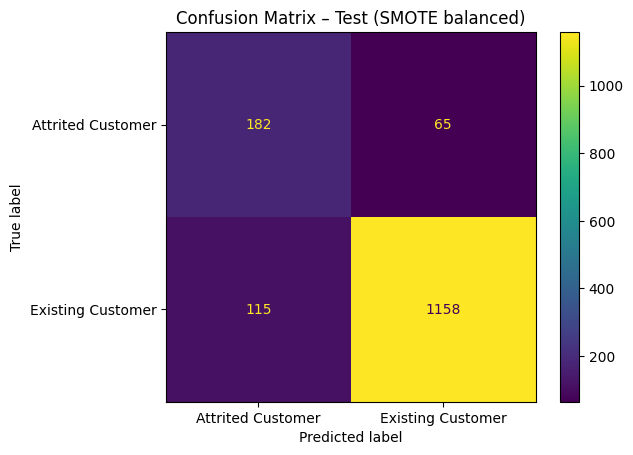

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_smote
)

plt.title("Confusion Matrix – Test (SMOTE balanced)")
plt.show()
